In [114]:
import random
from pathlib import Path

import sqlite3

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "fifa-2026"
DB_PATH = PROJECT_ROOT / "db" / "fifa2026.db"
DB_PATH.parent.mkdir(exist_ok=True)

PERMA_SEED = 42
random.seed(PERMA_SEED)
np.random.seed(PERMA_SEED)

In [115]:
def q(sql, params=None):
    with sqlite3.connect(DB_PATH) as c:
        return pd.read_sql_query(sql, c, params=params)

In [116]:
final_dataset = q("""
WITH
squad_totals AS (
    SELECT
        team_id,
        AVG((julianday('2026-06-11') - julianday(date_of_birth)) / 365.25) AS squad_age,
        SUM(caps) AS total_caps,
        SUM(goals) AS goals_sum
    FROM squads_and_players
    GROUP BY team_id
),
match_multiplier AS (
    SELECT 
        match_id,
        date, 
        home_team_id AS team_id,
        home_score AS goals_for, 
        away_score AS goals_against
    FROM matches
    UNION ALL
    SELECT 
        match_id, 
        date, 
        away_team_id,
        away_score,
        home_score
    FROM matches
),
team_timeline AS (
    SELECT
        match_id,
        team_id,
        julianday(date) - julianday(LAG(date) OVER w) AS rest_days,
        AVG(goals_for - goals_against) OVER (
            PARTITION BY team_id
            ORDER BY date, match_id
            ROWS BETWEEN 3 PRECEDING AND 1 PRECEDING
        ) AS recent_form
    FROM match_multiplier
    WINDOW w AS (PARTITION BY team_id ORDER BY date, match_id)
)
SELECT
    matches.match_id,
    matches.home_team_id,
    matches.away_team_id,
    t1.elo_rating - t2.elo_rating AS elo_rating_difference,
    home.squad_age - away.squad_age AS squad_age_difference,
    home.total_caps - away.total_caps AS caps_difference,
    home.goals_sum - away.goals_sum AS goal_total_difference,
    COALESCE(tl_home.rest_days, 10) - COALESCE(tl_away.rest_days, 10) AS rest_days_difference,
    stages.is_knockout AS is_knockout,
    (t1.fifa_code = venues.country) - (t2.fifa_code = venues.country) AS host_advantage,
    COALESCE(tl_home.recent_form, 0) - COALESCE(tl_away.recent_form, 0) AS form_difference,
    matches.home_score - matches.away_score AS goal_difference
FROM matches
JOIN teams AS t1 ON t1.team_id = matches.home_team_id
JOIN teams AS t2 ON t2.team_id = matches.away_team_id
JOIN venues ON venues.venue_id = matches.venue_id
JOIN tournament_stages AS stages ON stages.stage_id = matches.stage_id
JOIN squad_totals AS home ON home.team_id = matches.home_team_id
JOIN squad_totals AS away ON away.team_id = matches.away_team_id
JOIN team_timeline AS tl_home ON tl_home.match_id = matches.match_id AND tl_home.team_id = matches.home_team_id
JOIN team_timeline AS tl_away ON tl_away.match_id = matches.match_id AND tl_away.team_id = matches.away_team_id
ORDER BY matches.match_id;
""")

In [117]:
>>> final_dataset.head()

,match_id,home_team_id,away_team_id,elo_rating_difference,squad_age_difference,caps_difference,goal_total_difference,rest_days_difference,is_knockout,host_advantage,form_difference,goal_difference
0,1,1,2,190,1.092297,699,54,0.0,0,1,0.0,2
1,2,3,4,60,0.444901,236,45,0.0,0,0,0.0,1
2,3,5,6,150,0.516190,360,40,0.0,0,1,0.0,0
3,4,13,14,125,-2.097615,272,74,0.0,0,1,0.0,3
4,5,7,8,-260,1.200653,438,91,0.0,0,0,0.0,0


In [118]:
>>> final_dataset.shape

(104, 12)

In [119]:
ID_COLS = ["match_id", "home_team_id", "away_team_id"]
TARGET = "goal_difference"

FEATURES = [clmn for clmn in final_dataset.columns if clmn not in ID_COLS + [TARGET]]

In [120]:
>>> FEATURES

['elo_rating_difference',
 'squad_age_difference',
 'caps_difference',
 'goal_total_difference',
 'rest_days_difference',
 'is_knockout',
 'host_advantage',
 'form_difference']

In [121]:
# works great! linear reg now

In [122]:
X_train, X_test, y_train, y_test = train_test_split(
    final_dataset[FEATURES], final_dataset[TARGET], test_size=0.2, random_state=PERMA_SEED
)

In [123]:
>>> X_train

,elo_rating_difference,squad_age_difference,caps_difference,goal_total_difference,rest_days_difference,is_knockout,host_advantage,form_difference
55,-65,1.643132,-46,-21,0.0,0,0,-1.000000
22,10,-3.451377,-971,-58,0.0,0,0,0.000000
76,-25,-0.955194,-95,-41,0.0,1,0,0.333333
44,360,-0.177960,204,140,0.0,0,0,2.000000
72,-175,-0.164271,-435,-68,0.0,1,0,-2.000000
...,...,...,...,...,...,...,...,...
71,250,1.353551,591,86,0.0,0,0,-1.000000
14,-300,-0.226189,0,22,0.0,0,0,0.000000
92,-110,1.287843,418,143,0.0,1,0,-0.666667
51,45,-3.051229,-973,-122,0.0,0,0,1.500000


In [124]:
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

In [125]:
r2 = r2_score(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
print(f"Test R^2:  {r2:.3f}")
print(f"Test RMSE: {rmse:.3f} goals")

pd.Series(model.coef_, index=FEATURES, name="coefficient").sort_values()

X_sm = sm.add_constant(X_train)
ols_fds = sm.OLS(y_train, X_sm).fit()
>>>ols_fds.summary()

Test R^2:  0.386
Test RMSE: 1.763 goals


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        goal_difference   R-squared:                       0.519
Model:                            OLS   Adj. R-squared:                  0.467
Method:                 Least Squares   F-statistic:                     9.981
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.58e-09
Time:                        11:04:32   Log-Likelihood:                -142.65
No. Observations:                  83   AIC:                             303.3
Df Residuals:                      74   BIC:                             325.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.2444      0.192      1.273      0.207      -0.138       0.627
elo_rating_difference     0.0064      0.001      6.889      0.000       0.005       0.008
squad_age_difference      0.0846      0.160      0.529      0.599      -0.234       0.403
caps_difference          -0.0013      0.001     -1.269      0.209      -0.003       0.001
goal_total_difference     0.0011      0.004      0.264      0.792      -0.007       0.009
rest_days_difference      0.1795      0.308      0.584      0.561      -0.433       0.792
is_knockout              -0.7783      0.388     -2.006      0.048      -1.551      -0.005
host_advantage            1.1681      0.581      2.012      0.048       0.011       2.325
form_difference          -0.0202      0.103     -0.197      0.845      -0.224       0.184
==============================================================================
Omnibus:                        0.126   Durbin-Watson:                   1.671
Prob(Omnibus):                  0.939   Jarque-Bera (JB):                0.286
Skew:                           0.067   Prob(JB):                        0.867
Kurtosis:                       2.745   Cond. No.                     1.24e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.24e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

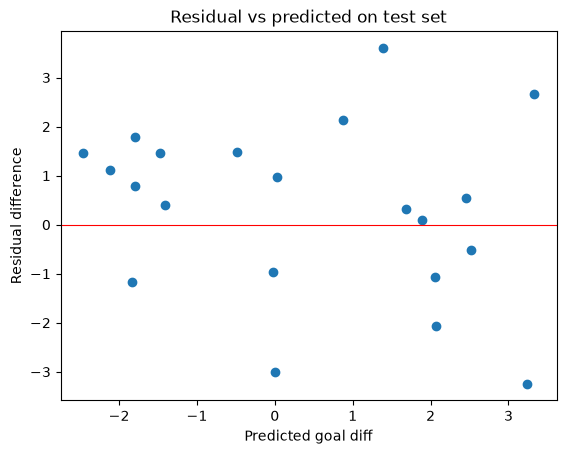

In [126]:
fig, axs = plt.subplots()

axs.scatter(pred, y_test - pred)
axs.axhline(0, color="red", linewidth=0.8)
axs.set_xlabel("Predicted goal diff")
axs.set_ylabel("Residual difference")
axs.set_title("Residual vs predicted on test set")
plt.show()

In [84]:
# DONE!

# SECOND QUESTION

In [91]:
goals_pred_ds = q("""
WITH
squad_totals AS (
    SELECT
        team_id,
        AVG((julianday('2026-06-11') - julianday(date_of_birth)) / 365.25) AS squad_age,
        SUM(goals) AS career_goals
        FROM squads_and_players
        GROUP BY team_id
),
team_match AS (
    SELECT match_id,
           date,
           home_team_id AS team_id,
           away_team_id AS opponent_id,
           home_score AS goals_scored,
           away_score AS goals_conceded
    FROM matches
    UNION ALL
    SELECT
        match_id,
        date,
        away_team_id,
        home_team_id,
        away_score,
        home_score
    FROM matches
),
team_timeline AS (
    SELECT
        match_id,
        team_id,
        opponent_id,
        goals_scored,
        julianday(date) - julianday(LAG (date) OVER w) AS rest_days,
        AVG(goals_scored) OVER (
            PARTITION BY team_id
            ORDER BY date, match_id
            ROWS BETWEEN 3 PRECEDING AND 1 PRECEDING
        ) AS recent_goals_scored
    FROM team_match
    WINDOW w AS (PARTITION BY team_id ORDER BY date, match_id)
)
SELECT
    tl.match_id,
    tl.team_id,
    tl.opponent_id,
    t.elo_rating AS team_elo,
    o.elo_rating AS opponent_elo,
    sq.squad_age AS team_squad_age,
    sq.career_goals AS team_career_goals,
    COALESCE(tl.rest_days, 10) AS team_rest_days,
    stages.is_knockout AS is_knockout,
    (t.fifa_code = venues.country) AS team_is_host,
    COALESCE(tl.recent_goals_scored, 0) AS team_recent_goals,
    tl.goals_scored AS goals_scored
FROM team_timeline AS tl
JOIN matches AS m ON m.match_id = tl.match_id
JOIN teams AS t ON t.team_id = tl.team_id
JOIN teams AS o ON o.team_id = tl.opponent_id
JOIN venues ON venues.venue_id = m.venue_id
JOIN tournament_stages AS stages ON stages.stage_id = m.stage_id
JOIN squad_totals AS sq ON sq.team_id = tl.team_id
ORDER BY tl.match_id, tl.team_id;
""")

In [92]:
>>> goals_pred_ds.head()

,match_id,team_id,opponent_id,team_elo,opponent_elo,team_squad_age,team_career_goals,team_rest_days,is_knockout,team_is_host,team_recent_goals,goals_scored
0,1,1,2,1810,1620,27.900700,120,10.0,0,1,0.0,2
1,1,2,1,1620,1810,26.808403,66,10.0,0,0,0.0,0
2,2,3,4,1800,1740,28.065708,144,10.0,0,0,0.0,2
3,2,4,3,1740,1800,27.620808,99,10.0,0,0,0.0,1
4,3,5,6,1795,1645,26.972674,134,10.0,0,1,0.0,1


In [93]:
ID_COLS_2 = ["match_id", "team_id", "opponent_id"]
TARGET_2 = "goals_scored"

FEATURES_2 = [clmn for clmn in goals_pred_ds.columns if clmn not in ID_COLS + [TARGET]]

In [94]:
>>> FEATURES_2

['team_id',
 'opponent_id',
 'team_elo',
 'opponent_elo',
 'team_squad_age',
 'team_career_goals',
 'team_rest_days',
 'is_knockout',
 'team_is_host',
 'team_recent_goals',
 'goals_scored']

In [95]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    goals_pred_ds[FEATURES_2], goals_pred_ds[TARGET_2], test_size=0.2, random_state=PERMA_SEED
)

In [97]:
model2 = LinearRegression().fit(X_train2, y_train2)
pred2 = model2.predict(X_test2)

In [98]:
r2_v2 = r2_score(y_test2, pred2)
rmse2 = mean_squared_error(y_test2, pred2) ** 0.5
print(f"Test R^2:  {r2_v2:.3f}")
print(f"Test RMSE: {rmse2:.3f} goals")

pd.Series(model2.coef_, index=FEATURES_2, name="coefficient").sort_values()

Test R^2:  1.000
Test RMSE: 0.000 goals


team_is_host        -1.095933e-15
is_knockout         -2.650713e-16
opponent_elo        -3.001352e-17
team_id             -1.284065e-17
team_career_goals   -3.808625e-18
opponent_id          5.190475e-18
team_elo             6.557492e-18
team_recent_goals    6.135254e-17
team_rest_days       1.008686e-16
team_squad_age       5.312171e-16
goals_scored         1.000000e+00
Name: coefficient, dtype: float64

In [128]:
X_sm = sm.add_constant(X_train2)
ols_second = sm.OLS(y_train2, X_sm).fit()
>>> ols_second.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           goals_scored   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 4.798e+30
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:05:30   Log-Likelihood:                 5359.5
No. Observations:                 166   AIC:                        -1.070e+04
Df Residuals:                     154   BIC:                        -1.066e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const             -5.329e-15   6.53e-15     -0.816      0.416   -1.82e-14    7.57e-15
team_id            6.418e-17   2.25e-17      2.850      0.005    1.97e-17    1.09e-16
opponent_id       -3.296e-17   2.13e-17     -1.548      0.124    -7.5e-17    9.09e-18
team_elo           -7.65e-18   1.51e-18     -5.072      0.000   -1.06e-17   -4.67e-18
opponent_elo       8.999e-18   1.32e-18      6.831      0.000     6.4e-18    1.16e-17
team_squad_age     5.551e-17    1.9e-16      0.293      0.770   -3.19e-16     4.3e-16
team_career_goals -4.445e-18   4.98e-18     -0.892      0.374   -1.43e-17    5.39e-18
team_rest_days    -1.388e-16   1.18e-16     -1.176      0.241   -3.72e-16    9.44e-17
is_knockout       -8.882e-16    5.4e-16     -1.644      0.102   -1.96e-15    1.79e-16
team_is_host       9.021e-16   8.36e-16      1.079      0.282    -7.5e-16    2.55e-15
team_recent_goals  1.388e-16   2.09e-16      0.665      0.507   -2.73e-16    5.51e-16
goals_scored          1.0000    1.6e-16   6.26e+15      0.000       1.000       1.000
==============================================================================
Omnibus:                        4.898   Durbin-Watson:                   2.193
Prob(Omnibus):                  0.086   Jarque-Bera (JB):                4.698
Skew:                          -0.297   Prob(JB):                       0.0955
Kurtosis:                       3.572   Cond. No.                     9.18e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.18e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""